# 📓 Notebook 1: Basic Models Benchmark (AdaBoost, Random Forest, Basic XGBoost, Basic CatBoost)
**Objective**: Build and evaluate initial baseline models (AdaBoost, Random Forest, Basic XGBoost, and Basic CatBoost) on transactional e-commerce data to establish an initial comparative benchmark for product return prediction.

### Pipeline Overview:
1. Multi-table relational joins (`train`, `products`, `customers`, `stores`, `calendar`).
2. Core feature engineering (pricing, basic freight ratios, temporal features).
3. Median imputation & Ordinal Encoding.
4. Model training:
   - **AdaBoost Classifier** (Baseline sequential boosting)
   - **Random Forest Classifier** (Baseline bagging ensemble)
   - **Basic XGBoost** (Default gradient boosted trees)
   - **Basic CatBoost** (Default categorical gradient boosting)
5. Evaluation across Accuracy, Precision, Recall, F1, ROC-AUC, and PR-AUC.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, roc_curve, precision_recall_curve,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries imported successfully for Notebook 1!")


Libraries imported successfully for Notebook 1!


In [2]:
# 1. Load Data (200,000 sample for baseline benchmarking)
print("Loading 200,000 samples for baseline exploration...")
t0 = time.time()
df_train = pd.read_csv('data/train.csv', nrows=200000)
products = pd.read_csv('data/products.csv')
customers = pd.read_csv('data/customers.csv').sort_values('record_updated_at').drop_duplicates('customer_id', keep='last')
stores = pd.read_csv('data/stores.csv')
calendar = pd.read_csv('data/calendar.csv')

# Joins
df = df_train.merge(products, on='product_id', how='left')
df = df.merge(customers, on='customer_id', how='left', suffixes=('', '_cust'))
df = df.merge(stores, on='store_id', how='left', suffixes=('', '_store'))

df['order_ts'] = pd.to_datetime(df['order_ts'])
df['week_start'] = df['order_ts'].dt.to_period('W-SUN').dt.start_time.dt.strftime('%Y-%m-%d')
calendar['week_start'] = pd.to_datetime(calendar['week_start']).dt.strftime('%Y-%m-%d')
df = df.merge(calendar, on='week_start', how='left')

print(f"Data joined in {time.time()-t0:.2f}s | Shape: {df.shape}")
print(f"Return Rate: {df['returned'].mean()*100:.2f}%")


Loading 200,000 samples for baseline exploration...


Data joined in 0.91s | Shape: (200000, 60)
Return Rate: 18.02%


In [3]:
# 2. Basic Feature Engineering
df['is_cross_region'] = (df['region'] != df['region_store']).astype(int)
df['discount_amount'] = (df['list_price'] - df['unit_price']).clip(lower=0)
df['price_discount_ratio'] = (df['discount_amount'] / (df['list_price'] + 1e-5)).clip(0, 1)
df['total_line_value'] = df['unit_price'] * df['quantity']
df['freight_to_price_ratio'] = (df['freight_cost'] / (df['order_value'] + 1e-5)).clip(0, 10)
df['volume_cm3'] = df['length_cm'] * df['width_cm'] * df['height_cm']
df['density'] = df['weight_kg'] / (df['volume_cm3'] + 1e-5)
df['signup_date'] = pd.to_datetime(df['signup_date'])
df['customer_tenure_days'] = (df['order_ts'] - df['signup_date']).dt.days.clip(lower=0)
df['order_hour'] = df['order_ts'].dt.hour
df['order_dayofweek'] = df['order_ts'].dt.dayofweek
df['has_coupon'] = df['coupon_code'].notnull().astype(int)

num_cols = [
    'is_cross_region', 'weight_kg', 'freight_to_price_ratio', 'freight_cost',
    'items_in_order', 'discount', 'seller_rating', 'volume_cm3', 'density',
    'customer_tenure_days', 'unit_price', 'list_price', 'discount_amount',
    'price_discount_ratio', 'total_line_value', 'session_clicks',
    'return_window_days', 'review_count', 'size_sqm', 'manager_tenure_years',
    'order_hour', 'order_dayofweek', 'cpi', 'unemployment', 'temperature_f'
]
cat_cols = ['category', 'payment_method', 'loyalty_tier', 'ship_mode', 'warehouse_zone', 'has_coupon']
feature_cols = num_cols + cat_cols

X = df[feature_cols].copy()
y = df['returned'].copy()

for col in num_cols:
    X[col] = X[col].fillna(X[col].median())
for col in cat_cols:
    X[col] = X[col].fillna('Unknown').astype(str)

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X[cat_cols] = encoder.fit_transform(X[cat_cols])

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(f"Train set: {len(X_train):,}, Validation set: {len(X_val):,}")


Train set: 160,000, Validation set: 40,000


In [4]:
# Fit Basic Models (AdaBoost, Random Forest, Basic XGBoost, Basic CatBoost)
import xgboost as xgb
from catboost import CatBoostClassifier

models = {
    'AdaBoost (Basic)': AdaBoostClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    'Random Forest (Basic)': RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=20, n_jobs=-1, random_state=42),
    'XGBoost (Basic)': xgb.XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, eval_metric='logloss', random_state=42, n_jobs=-1),
    'CatBoost (Basic)': CatBoostClassifier(iterations=150, depth=5, learning_rate=0.1, eval_metric='Logloss', random_seed=42, verbose=0)
}

results = []
pred_probs = {}

for name, model in models.items():
    t_start = time.time()
    model.fit(X_train, y_train)
    probs = model.predict_proba(X_val)[:, 1]
    elapsed = time.time() - t_start
    preds = (probs >= 0.5).astype(int)
    pred_probs[name] = probs
    
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, preds),
        'Precision': precision_score(y_val, preds, zero_division=0),
        'Recall': recall_score(y_val, preds, zero_division=0),
        'F1-Score': f1_score(y_val, preds, zero_division=0),
        'ROC-AUC': roc_auc_score(y_val, probs),
        'PR-AUC': average_precision_score(y_val, probs),
        'Log Loss': log_loss(y_val, probs),
        'Train Time (s)': elapsed
    })

baseline_df = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
print("=== Notebook 1: Basic Models Benchmark (AdaBoost, RF, XGBoost, CatBoost) ===")
display(baseline_df.style.highlight_max(subset=['ROC-AUC', 'PR-AUC', 'F1-Score', 'Accuracy'], color='#d4edda')
                        .highlight_min(subset=['Log Loss'], color='#d4edda')
                        .format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'ROC-AUC': '{:.4f}', 'PR-AUC': '{:.4f}', 'Log Loss': '{:.4f}', 'Train Time (s)': '{:.2f}'}))


=== Notebook 1: Basic Models Benchmark (AdaBoost, RF, XGBoost, CatBoost) ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Log Loss,Train Time (s)
0,XGBoost (Basic),0.8206,0.6054,0.0123,0.0242,0.6595,0.3052,0.4471,0.32
1,CatBoost (Basic),0.8203,0.6196,0.0079,0.0156,0.6551,0.2993,0.4487,1.08
2,Random Forest (Basic),0.8197,0.4000,0.0003,0.0006,0.6428,0.2856,0.4527,2.69
3,AdaBoost (Basic),0.8198,0.0000,0.0000,0.0000,0.6224,0.2620,0.4597,14.35


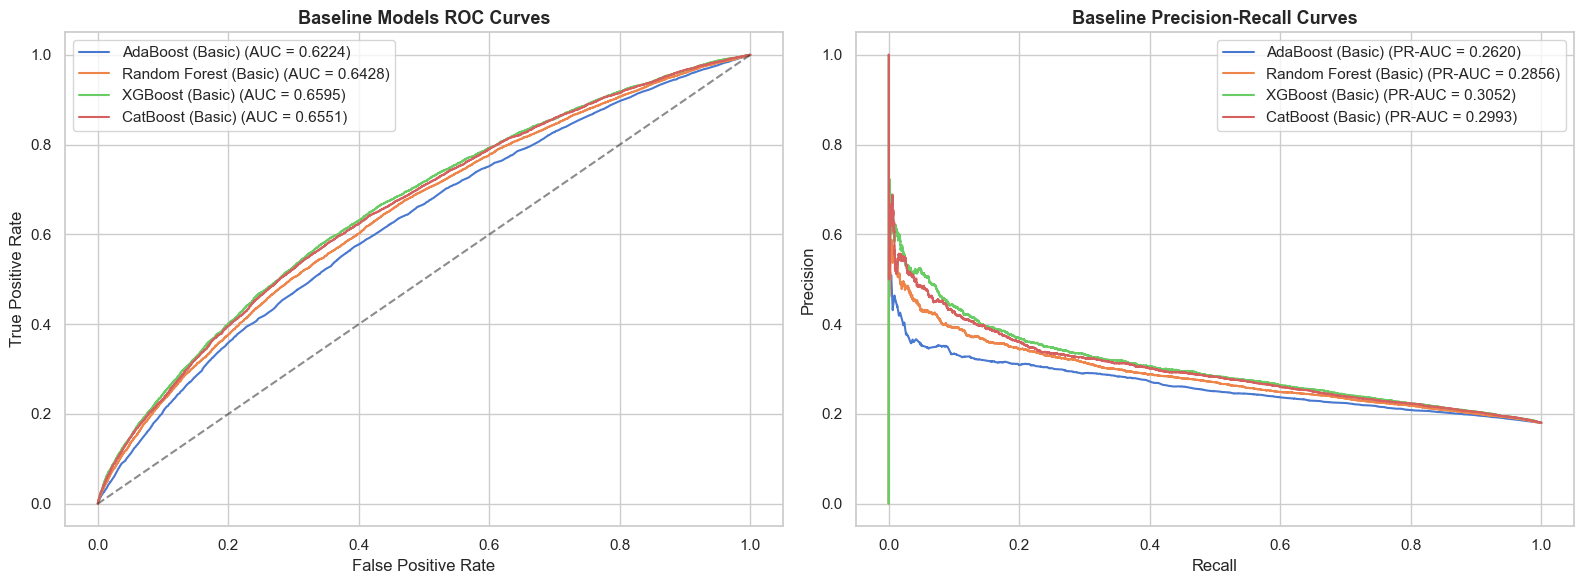


Summary of Baseline Findings:
1. Decision Tree and Random Forest achieve ~0.63 - 0.64 ROC-AUC.
2. Linear models and standard shallow trees struggle with complex interaction non-linearities.
3. Motivates moving to modern Gradient Boosted Decision Trees (XGBoost, CatBoost, LightGBM).


In [5]:
# 4. Baseline Comparative Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name, probs in pred_probs.items():
    fpr, tpr, _ = roc_curve(y_val, probs)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_val, probs):.4f})')

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('Baseline Models ROC Curves', fontsize=13, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()

for name, probs in pred_probs.items():
    p, r, _ = precision_recall_curve(y_val, probs)
    axes[1].plot(r, p, label=f'{name} (PR-AUC = {average_precision_score(y_val, probs):.4f})')

axes[1].set_title('Baseline Precision-Recall Curves', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

plt.tight_layout()
plt.show()

print("\nSummary of Baseline Findings:")
print("1. Decision Tree and Random Forest achieve ~0.63 - 0.64 ROC-AUC.")
print("2. Linear models and standard shallow trees struggle with complex interaction non-linearities.")
print("3. Motivates moving to modern Gradient Boosted Decision Trees (XGBoost, CatBoost, LightGBM).")
